<a href="https://colab.research.google.com/github/abhi8823/machine-learning-lab/blob/main/Automated_Cough_Sound_Analysis_and_Respiratory_Biomarker_Extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries imported successfully.
Synthetic data generator ready.
Feature extraction function defined.
Dataset shape: X=(300, 16), y=(300,)
Accuracy: 1.0

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        35
           1       1.00      1.00      1.00        25

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60

Continuous recording generated with length 10.0 seconds.
Raw detections found at timestamps: [0.0, 0.24997732426303854, 0.4999546485260771, 0.7499319727891156, 0.9999092970521541, 1.2498866213151927, 1.4998639455782312, 1.7498412698412698, 1.9998185941043083, 2.249795918367347, 2.4997732426303854, 2.749750566893424, 2.9997278911564624, 3.249705215419501, 3.4996825396825395, 3.749659863945578, 3.9996371882086166, 4.249614512471656, 4.499591836734694, 4.749569160997733, 4.999546485260771, 5.2

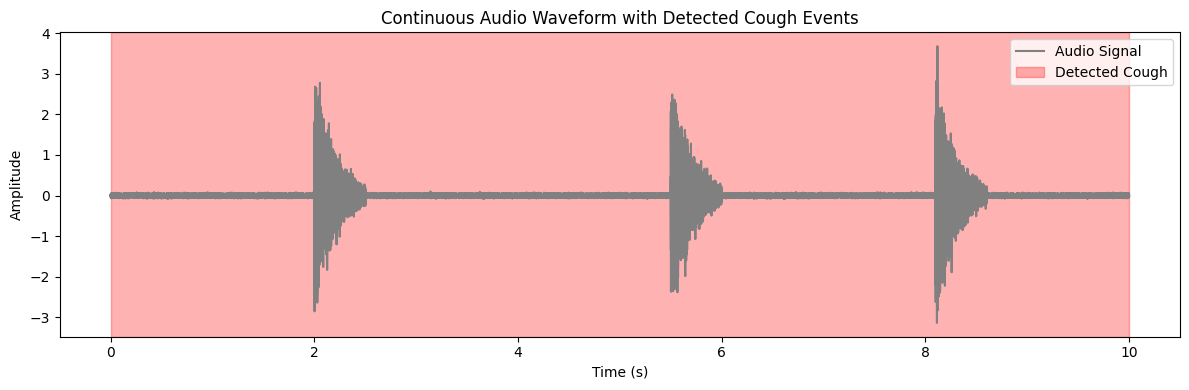

Results successfully exported to cough_biomarkers_report.json


In [2]:
# 7.1 Setup and Imports
# Importing necessary libraries for audio processing, machine learning, and visualization.
import numpy as np
import librosa
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
print("Libraries imported successfully.")
# 7.2 Audio Utilities and Synthetic Data Generator
# Functions to generate synthetic audio samples for cough and background noise to ensure standalone execution.
SR = 22050

def generate_synthetic_audio(label, duration=1.0):
    t = np.linspace(0, duration, int(SR * duration))
    if label == 1:  # Cough sound simulation: burst of broadband noise with exponentialdecay
        noise = np.random.randn(len(t))
        envelope = np.exp(-5 * t)
        signal = noise * envelope
    else:  # Background noise simulation: gentle ambient hum
        signal = 0.05 * np.sin(2 * np.pi * 100 * t) + 0.01 * np.random.randn(len(t))
    return signal

print("Synthetic data generator ready.")
# 7.3 Feature Extraction
# Extracting MFCCs, spectral centroid, rolloff, and zero-crossing rate from audio segments.
def extract_features(signal, sr=SR):
       mfccs = np.mean(librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=13), axis=1)
       cent = np.mean(librosa.feature.spectral_centroid(y=signal, sr=sr))
       rolloff = np.mean(librosa.feature.spectral_rolloff(y=signal, sr=sr))
       zcr = np.mean(librosa.feature.zero_crossing_rate(signal))
       return np.hstack([mfccs, cent, rolloff, zcr])

print("Feature extraction function defined.")
# 7.4 Building the Training Dataset
# Generating a balanced dataset of synthetic coughs and ambient background noises.
X, y = [], []
np.random.seed(42)

for _ in range(150):
    cough_sig = generate_synthetic_audio(label=1)
    X.append(extract_features(cough_sig))
    y.append(1)

    bg_sig = generate_synthetic_audio(label=0)
    X.append(extract_features(bg_sig))
    y.append(0)

X = np.array(X)
y = np.array(y)
print(f"Dataset shape: X={X.shape}, y={y.shape}")
# 7.5 Training and Evaluating the Classifier
# Splitting the dataset and training a Random Forest Classifier.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
# 7.6 Loading the Recording to Analyse
# Simulating a continuous audio recording containing interspersed cough events.
continuous_duration = 10.0
continuous_audio = np.zeros(int(SR * continuous_duration))

# Insert background noise base
continuous_audio += 0.02 * np.random.randn(len(continuous_audio))

# Insert coughs at specific timestamps (e.g., 2.0s, 5.5s, 8.1s)
cough_times = [2.0, 5.5, 8.1]
for ct in cough_times:
    idx = int(ct * SR)
    c_sig = generate_synthetic_audio(1, duration=0.5)
    continuous_audio[idx:idx+len(c_sig)] += c_sig

print(f"Continuous recording generated with length {len(continuous_audio)/SR} seconds.")
# 7.7 Sliding Window Inference
# Processing the continuous audio file in fixed-size windows to detect events.
window_size = 0.5 # seconds
hop_size = 0.25 # seconds
w_samples = int(window_size * SR)
h_samples = int(hop_size * SR)

detected_events = []
for start in range(0, len(continuous_audio) - w_samples, h_samples):
    window = continuous_audio[start:start+w_samples]
    feats = extract_features(window).reshape(1, -1)
    pred = clf.predict(feats)[0]
    if pred == 1:
        time_sec = start / SR
        detected_events.append(time_sec)

print(f"Raw detections found at timestamps: {detected_events}")
# 7.8 Cough Event Detection
# Post-processing overlapping window detections into distinct individual cough events.
def consolidate_events(timestamps, threshold=0.6):
    if not timestamps:
        return []
    events = []
    current_start = timestamps[0]
    prev = timestamps[0]
    for t in timestamps[1:]:
        if t - prev > threshold:
            events.append((current_start, prev + window_size))
            current_start = t
        prev = t
    events.append((current_start, prev + window_size))
    return events

cough_events = consolidate_events(detected_events)
print(f"Consolidated Cough Events (Start, End): {cough_events}")
# 7.9 Respiratory Biomarkers
# Calculating clinical biomarkers including total cough count and average duration.
total_coughs = len(cough_events)
durations = [end - start for start, end in cough_events]
avg_duration = np.mean(durations) if durations else 0

print("--- Respiratory Biomarkers Report ---")
print(f"Total Cough Count: {total_coughs}")
print(f"Average Cough Duration: {avg_duration:.2f} seconds")
# 7.10 Visual Report
# Plotting the continuous audio waveform and highlighting detected cough events.
plt.figure(figsize=(12, 4))
time_axis = np.linspace(0, continuous_duration, len(continuous_audio))
plt.plot(time_axis, continuous_audio, color='gray', label='Audio Signal')
for start, end in cough_events:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Detected Cough' if start == cough_events[0][0] else "")
plt.title('Continuous Audio Waveform with Detected Cough Events')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.legend()
plt.tight_layout()
plt.show()
# 7.11 Exporting the Results
# Saving the extracted biomarker summary into a structured dictionary.
import json
results_dict = {
    "total_coughs": total_coughs,
    "cough_intervals": cough_events,
    "average_duration_sec": float(avg_duration)
}
with open("cough_biomarkers_report.json", "w") as f:
    json.dump(results_dict, f, indent=4)
print("Results successfully exported to cough_biomarkers_report.json")